# 확률분포로 손실 함수 이해하기
모델이 정답에 부여한 확률(연속값이면 밀도)로 우도를 구성한다. 관측이 입력에 조건부로 독립이면 우도를 곱하고, 로그를 취하면 합이 된다. 로그가 증가 함수이므로 **우도 최대화**는 **음의 로그우도(NLL) 최소화**와 같은 최적화 문제다.

## 1. 정규분포의 PDF와 베르누이 분포의 PMF

- 정규분포는 연속값을 설명한다. $\mathcal N(\mu,\sigma^2)$의 두 번째 인자는 분산이다. 따라서 $\mathcal N(2,0.5)$의 표준편차는 $\sqrt{0.5}$이며 곡선 아래 구간의 면적이 확률이다.
- 베르누이 분포는 0과 1만 갖는다. $P(Y=1)=p$, $P(Y=0)=1-p$이므로 두 막대의 합은 1이다.

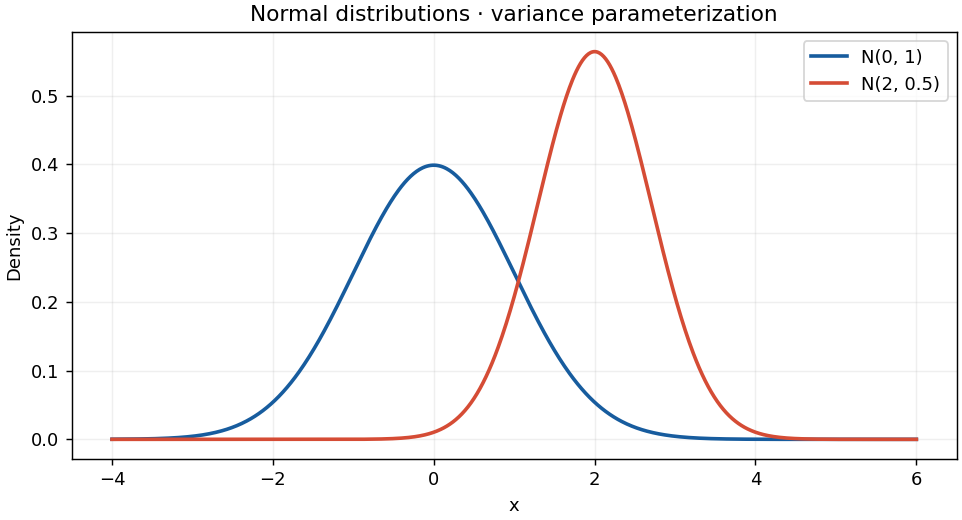

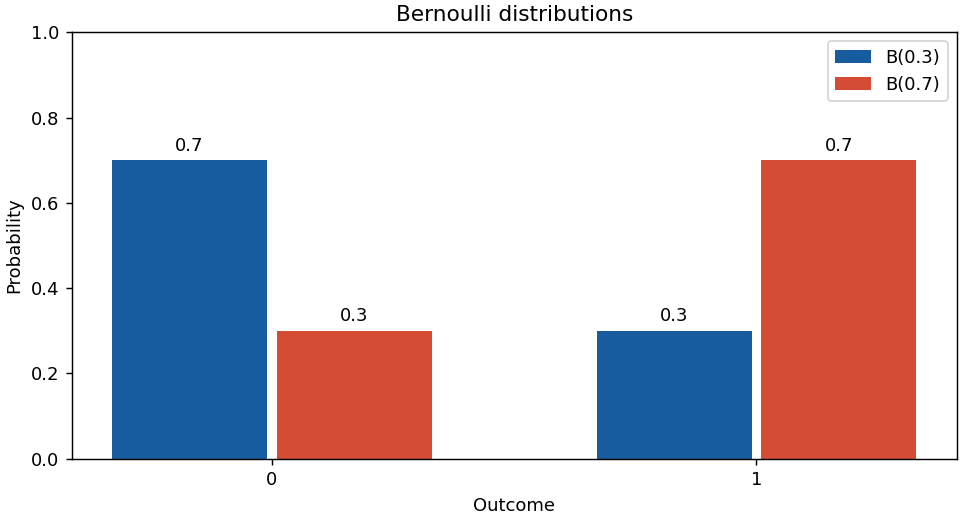

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display

np.random.seed(42)
root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
out = root / "outputs"
out.mkdir(exist_ok=True)

def normal_pdf(x, mean, variance):
    """정규분포의 평균과 분산으로 확률밀도를 계산한다."""
    return np.exp(-(x - mean)**2 / (2 * variance)) / np.sqrt(2 * np.pi * variance)

def bernoulli_pmf(p):
    """값 0과 1의 확률 질량을 순서대로 반환한다."""
    return np.array([1 - p, p])

def save_and_display(fig, name):
    """PNG를 저장하고 같은 결과를 노트북에 표시한다."""
    path = out / name
    fig.savefig(path, dpi=130)
    plt.close(fig)
    display(Image(filename=str(path)))

x = np.linspace(-4, 6, 801)
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
ax.plot(x, normal_pdf(x, 0, 1), label="N(0, 1)", color="#175c9e", lw=2)
ax.plot(x, normal_pdf(x, 2, 0.5), label="N(2, 0.5)", color="#d54c35", lw=2)
ax.set(title="Normal distributions · variance parameterization", xlabel="x", ylabel="Density")
ax.grid(alpha=0.2)
ax.legend()
save_and_display(fig, "07_normal_pdf.png")

values = np.array([0, 1])
fig, ax = plt.subplots(figsize=(7.4, 4), layout="constrained")
for p, offset, color in ((0.3, -0.17, "#175c9e"), (0.7, 0.17, "#d54c35")):
    bars = ax.bar(values + offset, bernoulli_pmf(p), width=0.32, label=f"B({p})", color=color)
    ax.bar_label(bars, fmt="%.1f", padding=3)
ax.set(title="Bernoulli distributions", xlabel="Outcome", ylabel="Probability",
       xticks=values, ylim=(0, 1))
ax.legend()
save_and_display(fig, "08_bernoulli_pmf.png")

## 2. 회귀: 정규 오차에서 MSE가 나오는 이유

예측값을 $\mu_i=f_\theta(x_i)$, 잔차를 $y_i-\mu_i$라고 하자. 잔차가 서로 독립이고 평균 0과 같은 고정 분산 $\sigma^2>0$을 가진 정규분포라면

$$p(y_i\mid x_i;\theta)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\!\left(-\frac{(y_i-\mu_i)^2}{2\sigma^2}\right).$$

곱의 음의 로그를 취하면
$$-\log\prod_{i=1}^n p(y_i\mid x_i;\theta)
=\frac{n}{2}\log(2\pi\sigma^2)+\frac{1}{2\sigma^2}\sum_{i=1}^n(y_i-\mu_i)^2
=\frac{n}{2}\log(2\pi\sigma^2)+\frac{n}{2\sigma^2}\operatorname{MSE}.$$

앞 항은 $\theta$에 무관하고 MSE 앞의 계수는 양수다. 따라서 두 목적함수를 최소화하는 $\theta$가 같다. 관측마다 분산이 다르면 제곱 오차에도 서로 다른 가중치가 생긴다.

## 3. 분류: 베르누이와 카테고리 분포에서 Cross-Entropy가 나오는 이유

**이진 분류.** 모델이 $p_i=P(Y_i=1\mid x_i)$를 내놓으면 실제 답 $y_i\in\{0,1\}$의 확률은 $p_i^{y_i}(1-p_i)^{1-y_i}$이다. 여러 관측의 음의 로그우도는
$$-\log\prod_i p_i^{y_i}(1-p_i)^{1-y_i}
=-\sum_i[y_i\log p_i+(1-y_i)\log(1-p_i)] = n\,\overline{\operatorname{BCE}}.$$

**다중 분류.** 정답을 원-핫 벡터 $t_{ic}$로, 모델이 클래스 $c$에 부여한 확률을 $p_{ic}$로 쓰면 정답 확률은 $\prod_c p_{ic}^{t_{ic}}$이다. 음의 로그우도는
$$-\log\prod_i\prod_c p_{ic}^{t_{ic}}
=-\sum_i\sum_c t_{ic}\log p_{ic}=n\,\overline{\operatorname{CE}}.$$

두 경우 모두 실제 정답에 부여한 확률이 낮을수록 $-\log p$가 커진다. 예를 들어 정답 확률이 0.8이면 손실은 약 0.223, 0.2면 약 1.609다.

## 4. 소프트맥스로 클래스 확률 만들기

로짓 $\mathbf z$를 $p_c=e^{z_c-m}/\sum_j e^{z_j-m}$, $m=\max_j z_j$로 바꾼다. 모든 지수에 공통으로 붙는 $e^{-m}$이 약분되므로 확률은 같고, 큰 로짓에서도 양의 방향 지수 오버플로를 막는다. 아래에서 정규화와 우도 관계를 수치로 확인한다.

In [2]:
def softmax(logits):
    """마지막 축의 최댓값을 빼고 안정적으로 정규화한다."""
    logits = np.asarray(logits, dtype=float)
    exp = np.exp(logits - np.max(logits, axis=-1, keepdims=True))
    return exp / np.sum(exp, axis=-1, keepdims=True)

logits = np.array([1000, 1001, 1002])
prob = softmax(logits)
error = abs(prob.sum() - 1)
assert error <= 1e-6
np.testing.assert_allclose(prob, softmax(logits - 1000), atol=1e-14, rtol=0)
print(f"Softmax {prob}; |sum - 1|={error:.3e} [PASS]")

y, mean, variance = np.array([0.2, 1.0, 2.1]), np.array([0.0, 1.3, 2.2]), 0.5
mse = np.mean((y - mean)**2)
nll = -np.log(normal_pdf(y, mean, variance)).sum()
np.testing.assert_allclose(nll, len(y) / 2 * (np.log(2 * np.pi * variance) + mse / variance))

y, p = np.array([1, 0]), np.array([0.8, 0.3])
nll = -np.log(p**y * (1 - p)**(1 - y)).sum()
np.testing.assert_allclose(nll, -np.sum(y * np.log(p) + (1 - y) * np.log1p(-p)))

p = softmax([[1, 2, 3], [3, 1, 2]])
labels = np.array([2, 0])
targets = np.eye(3)[labels]
np.testing.assert_allclose(-np.log(p[np.arange(2), labels]).sum(),
                           -np.sum(targets * np.log(p)))
print("Gaussian, Bernoulli and categorical NLL identities [PASS]")

Softmax [0.09003057 0.24472847 0.66524096]; |sum - 1|=1.110e-16 [PASS]
Gaussian, Bernoulli and categorical NLL identities [PASS]


## 5. 소프트맥스와 Cross-Entropy의 기울기

정답 원-핫 벡터를 $t$, 정답 클래스를 $k$라 하면 샘플 하나의 손실은
$$L=-\sum_c t_c\log p_c=-z_k+\log\sum_j e^{z_j}$$
이다. 로짓 $z_c$로 미분하면 $-t_c+\dfrac{e^{z_c}}{\sum_j e^{z_j}}=p_c-t_c$, 즉 $\nabla_z L=p-t$다. 이진 분류에서 $\partial L/\partial z_2=\hat y-y$였던 것과 같은 꼴이다. 아래에서 중심차분으로 확인한다.

In [3]:
def cross_entropy(logits, target):
    """원-핫 정답 target에 대한 다중 분류 Cross-Entropy (샘플 하나)."""
    shifted = logits - np.max(logits)
    return np.logaddexp.reduce(shifted) - target @ shifted


logits = np.array([2.0, 1.0, 0.1])
target = np.array([1.0, 0.0, 0.0])
analytic = softmax(logits) - target
h = 1e-6
numeric = np.array([
    (cross_entropy(logits + h * e, target) - cross_entropy(logits - h * e, target)) / (2 * h)
    for e in np.eye(len(logits))
])
gap = float(np.max(np.abs(analytic - numeric)))
assert gap <= 1e-8
print(f"Softmax + CE gradient p - t = {np.round(analytic, 6)}; max error {gap:.3e} [PASS]")

Softmax + CE gradient p - t = [-0.340999  0.242433  0.098566]; max error 3.399e-11 [PASS]
